# Etapa 09 — Demonstração do código e do agente

**Projeto Integrador IV** · Gestão Preditiva de Estoque com Inteligência Artificial  
**Integrantes:** Carlos Eduardo · Adryan Kevin · Eduardo Mendonça · Gabriel · Kevin Maykel  
**Apresentação final:** 16/12/2026

---

Este notebook demonstra, rodando do início ao fim, as **duas rodadas** exigidas pelas
atividades 06 a 08:

| | Rodada 1 — na mão | Rodada 2 — engenharia de prompt |
|---|---|---|
| Como foi feito | O grupo digitou o código | Um agente escreveu, orquestrado por prompt |
| Onde vive | Neste notebook (Entregável 04) | `backend/src/domain/` do sistema |
| O que calcula | Função de aptidão + algoritmo genético | **Exatamente a mesma coisa** |

No fim, provamos que as duas implementações produzem **o mesmo resultado**.


## 0. Preparação do ambiente

A célula abaixo funciona nos dois cenários: se o repositório já estiver na máquina, usa
ele; se estiver no Google Colab, clona do GitHub.


In [1]:
import os, subprocess, sys, pathlib

REPO_URL = 'https://github.com/KMLegend/projeto-integrador-ia.git'

def localizar_repositorio() -> pathlib.Path:
    # 1) repositório já presente (execução local)
    for base in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (base / 'backend' / 'src' / 'domain').is_dir():
            return base
    # 2) Google Colab: clona
    destino = pathlib.Path('/content/projeto-integrador-ia')
    if not destino.exists():
        print('Clonando o repositório...')
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(destino)], check=True)
    return destino

REPO = localizar_repositorio()
sys.path.insert(0, str(REPO / 'backend' / 'src'))
print(f'Repositório: {REPO}')
print(f'Python: {sys.version.split()[0]}  (o domínio exige 3.10+)')


Repositório: /Users/ti/Documents/Projetos/faculdade/projeto-integrador
Python: 3.12.16  (o domínio exige 3.10+)


## 1. O cenário de decisão

Seis produtos de uma cesta básica. O modelo de Machine Learning (Entregável 03) já previu a
demanda semanal de cada um; daí calculamos quanto falta para cobrir um ciclo de 4 semanas.

O orçamento **não cobre** a necessidade — é esse déficit que o algoritmo genético administra.


In [2]:
CENARIO = [
    # (sku,            produto,            preço unitário, necessidade de reposição)
    ('ARROZ-5KG',        'Arroz 5kg',          29.89,  0),
    ('CAFE-500G',        'Café 500g',          18.78, 48),
    ('DETERGENTE-500ML', 'Detergente 500ml',    3.07,  0),
    ('FEIJAO-1KG',       'Feijão 1kg',          9.55,  0),
    ('LEITE-UHT-1L',     'Leite UHT 1L',        5.86, 98),
    ('REFRIGERANTE-2L',  'Refrigerante 2L',    10.76,  0),
]
ORCAMENTO = 1000.00

precos  = [p for _, _, p, _ in CENARIO]
necess  = [n for _, _, _, n in CENARIO]

custo_total_necessidade = sum(p * n for _, _, p, n in CENARIO)
print(f'Necessidade total .......... {sum(necess)} unidades')
print(f'Custo para atender 100% .... R$ {custo_total_necessidade:,.2f}')
print(f'Orçamento disponível ....... R$ {ORCAMENTO:,.2f}')
print(f'Déficit .................... R$ {custo_total_necessidade - ORCAMENTO:,.2f}')


Necessidade total .......... 146 unidades
Custo para atender 100% .... R$ 1,475.72
Orçamento disponível ....... R$ 1,000.00
Déficit .................... R$ 475.72


---

## 2. Rodada 1 — implementação escrita à mão

Código do Entregável 04, digitado pelo grupo nos encontros de 28/10 e 04/11, **sem agente**.

A função de aptidão recompensa cobertura e penaliza produto desabastecido:

$$\text{fitness} = \text{cobertura}(\%) \times 10 - \text{produtos em risco} \times 5$$


In [3]:
def ajustar_ao_orcamento(solucao):
    """Limita quantidades à necessidade e remove unidades até caber no orçamento."""
    solucao = [min(max(int(q), 0), necess[i]) for i, q in enumerate(solucao)]
    while sum(solucao[i] * precos[i] for i in range(len(solucao))) > ORCAMENTO:
        candidatos = [i for i, q in enumerate(solucao) if q > 0]
        if not candidatos:
            break
        # remove uma unidade do item mais caro: perde o mínimo de cobertura por real liberado
        indice = max(candidatos, key=lambda i: precos[i])
        solucao[indice] -= 1
    return solucao


def avaliar(solucao):
    """Indicadores e pontuação de uma estratégia de reposição."""
    solucao = ajustar_ao_orcamento(solucao)
    custo = sum(solucao[i] * precos[i] for i in range(len(solucao)))
    atendido = sum(min(solucao[i], necess[i]) for i in range(len(solucao)))
    total = sum(necess)
    percentual = 100 * atendido / total if total else 100.0
    em_risco = sum(1 for i in range(len(solucao)) if solucao[i] < necess[i])
    return {'solucao': solucao, 'custo': custo, 'atendido': atendido,
            'percentual': percentual, 'em_risco': em_risco,
            'fitness': percentual * 10 - em_risco * 5}


def solucao_ingenua():
    """Linha de base: divide o orçamento igualmente entre os produtos."""
    parcela = ORCAMENTO / len(CENARIO)
    return ajustar_ao_orcamento([int(parcela // p) for p in precos])


print('Funções da Rodada 1 definidas.')


Funções da Rodada 1 definidas.


### O algoritmo genético


In [4]:
import random

TAMANHO_POPULACAO, GERACOES, TAXA_MUTACAO = 60, 100, 0.20
PAIS, ELITE = 20, 2
rng = random.Random(42)   # semente fixa: a demonstração é reproduzível


def criar_individuo():
    return ajustar_ao_orcamento([rng.randint(0, n) if n > 0 else 0 for n in necess])


def cruzar(pai, mae):
    return ajustar_ao_orcamento(
        [pai[i] if rng.random() < 0.5 else mae[i] for i in range(len(CENARIO))])


def mutar(individuo):
    filho = list(individuo)
    if rng.random() < TAXA_MUTACAO:
        i = rng.randrange(len(CENARIO))
        filho[i] = max(0, filho[i] + rng.randint(-10, 10))
    return ajustar_ao_orcamento(filho)


populacao = [criar_individuo() for _ in range(TAMANHO_POPULACAO)]
historico = []

for geracao in range(GERACOES):
    populacao.sort(key=lambda ind: avaliar(ind)['fitness'], reverse=True)
    historico.append(avaliar(populacao[0])['fitness'])
    pais = populacao[:PAIS]
    nova = pais[:ELITE]                      # elitismo: a solução nunca piora
    while len(nova) < TAMANHO_POPULACAO:
        nova.append(mutar(cruzar(rng.choice(pais), rng.choice(pais))))
    populacao = nova

melhor_rodada1 = avaliar(max(populacao, key=lambda ind: avaliar(ind)['fitness']))
ingenua = avaliar(solucao_ingenua())

print(f"Divisão igual ....... custo R$ {ingenua['custo']:7.2f} | cobertura {ingenua['percentual']:5.1f}%"
      f" | risco {ingenua['em_risco']} | fitness {ingenua['fitness']:8.4f}")
print(f"Algoritmo genético .. custo R$ {melhor_rodada1['custo']:7.2f} | cobertura {melhor_rodada1['percentual']:5.1f}%"
      f" | risco {melhor_rodada1['em_risco']} | fitness {melhor_rodada1['fitness']:8.4f}")
print(f"\nPlano recomendado: {melhor_rodada1['solucao']}")
for (sku, nome, preco, nec), qtd in zip(CENARIO, melhor_rodada1['solucao']):
    if qtd:
        print(f'   {nome:<20} {qtd:>3} de {nec:>3} un.   R$ {qtd * preco:8.2f}')


Divisão igual ....... custo R$  314.32 | cobertura  24.7% | risco 2 | fitness 236.5753
Algoritmo genético .. custo R$  987.44 | cobertura  82.2% | risco 1 | fitness 816.9178

Plano recomendado: [0, 22, 0, 0, 98, 0]
   Café 500g             22 de  48 un.   R$   413.16
   Leite UHT 1L          98 de  98 un.   R$   574.28


### A curva de convergência

O elitismo garante que a melhor solução nunca piora — por isso a curva só sobe.


Matplotlib is building the font cache; this may take a moment.


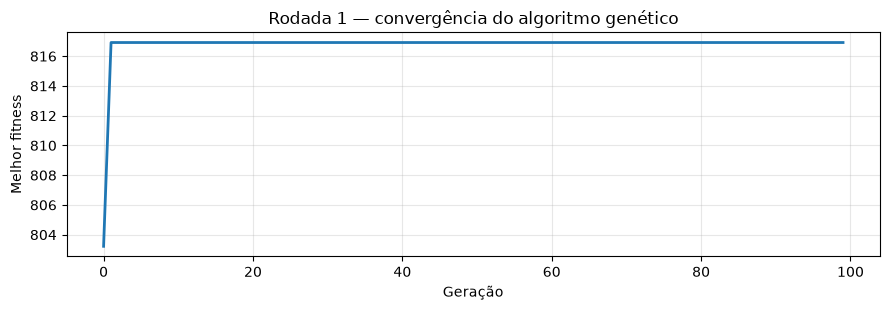

Primeira geração: 803.2192   Última: 816.9178
Decrescimentos ao longo das gerações: 0


In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 3.2))
plt.plot(historico, linewidth=2)
plt.title('Rodada 1 — convergência do algoritmo genético')
plt.xlabel('Geração'); plt.ylabel('Melhor fitness')
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

print(f'Primeira geração: {historico[0]:.4f}   Última: {historico[-1]:.4f}')
print('Decrescimentos ao longo das gerações:',
      sum(1 for i in range(1, len(historico)) if historico[i] < historico[i-1] - 1e-9))


---

## 3. Rodada 2 — a mesma função, construída por engenharia de prompt

Nenhuma linha abaixo foi digitada pelo grupo. O código veio de um agente orquestrado por
prompt, a partir da especificação em `.context/` — e está organizado em camadas, com
objetos de domínio em vez de listas e números soltos.


In [6]:
from domain.model.budget_constraint import BudgetConstraint
from domain.model.catalog_item import CatalogItem
from domain.model.purchase_plan import PurchasePlan
from domain.model.quantity import Quantity
from domain.model.replenishment_item import ReplenishmentItem
from domain.model.replenishment_scenario import ReplenishmentScenario
from domain.model.sku import Sku
from domain.model.unit_price import UnitPrice
from domain.policy.weighted_fitness_policy import WeightedFitnessPolicy

# o reparo em lote (D-19) só existe nas versões mais recentes; cai no original se faltar
try:
    from domain.policy.batched_budget_plan_repair import BatchedBudgetPlanRepair as Reparo
    nome_reparo = 'BatchedBudgetPlanRepair (D-19)'
except ImportError:
    from domain.policy.budget_aware_plan_repair import BudgetAwarePlanRepair as Reparo
    nome_reparo = 'BudgetAwarePlanRepair'

cenario_sistema = ReplenishmentScenario.of_items([
    ReplenishmentItem(CatalogItem(Sku(sku), UnitPrice.from_reais(f'{preco:.2f}')),
                      Quantity.of(nec))
    for sku, _, preco, nec in CENARIO
])
orcamento_sistema = BudgetConstraint.from_reais(f'{ORCAMENTO:.2f}')
reparo = Reparo(orcamento_sistema)
politica = WeightedFitnessPolicy.standard()


def avaliar_sistema(unidades):
    plano = reparo.repair(PurchasePlan.of_units(tuple(unidades)), cenario_sistema)
    return {
        'solucao': list(plano.units_for_serialization()),
        'custo': float(cenario_sistema.total_cost_of(plano).value_for_serialization()),
        'fitness': politica.evaluate(plano, cenario_sistema).fitness_value(),
    }


print(f'Reparo em uso: {nome_reparo}')
r2 = avaliar_sistema(melhor_rodada1['solucao'])
print(f"Mesmo plano, avaliado pelo sistema: custo R$ {r2['custo']:.2f} | fitness {r2['fitness']:.4f}")


Reparo em uso: BatchedBudgetPlanRepair (D-19)
Mesmo plano, avaliado pelo sistema: custo R$ 987.44 | fitness 816.9178


---

## 4. Prova de equivalência

As duas rodadas são códigos independentes. Se produzirem o mesmo número em milhares de
casos, a reimplementação por prompt preservou a regra de negócio.


In [7]:
casos_nomeados = {
    'baseline (divisão igual)': ingenua['solucao'],
    'plano ótimo':              melhor_rodada1['solucao'],
    'plano vazio':              [0] * len(CENARIO),
    'acima da necessidade':     [999] * len(CENARIO),
}

print(f"{'caso':<26} {'Rodada 1':>12} {'Rodada 2':>12}   situação")
print('-' * 68)
tudo_igual = True
for nome, plano in casos_nomeados.items():
    f1 = avaliar(list(plano))['fitness']
    f2 = avaliar_sistema(plano)['fitness']
    igual = abs(f1 - f2) < 1e-6
    tudo_igual &= igual
    print(f'{nome:<26} {f1:>12.4f} {f2:>12.4f}   {"idêntico" if igual else "DIVERGE"}')

sorteio = random.Random(7)
divergencias = 0
for _ in range(3000):
    plano = [sorteio.randint(0, 150) for _ in range(len(CENARIO))]
    if abs(avaliar(list(plano))['fitness'] - avaliar_sistema(plano)['fitness']) > 1e-6:
        divergencias += 1

print('-' * 68)
print(f'Teste aleatório: {divergencias} divergências em 3.000 planos sorteados')
print()
print('RESULTADO:', 'as duas implementações são equivalentes'
      if tudo_igual and divergencias == 0 else 'HÁ DIVERGÊNCIA')


caso                           Rodada 1     Rodada 2   situação
--------------------------------------------------------------------
baseline (divisão igual)       236.5753     236.5753   idêntico
plano ótimo                    816.9178     816.9178   idêntico
plano vazio                    -10.0000     -10.0000   idêntico
acima da necessidade           816.9178     816.9178   idêntico
--------------------------------------------------------------------
Teste aleatório: 0 divergências em 3.000 planos sorteados

RESULTADO: as duas implementações são equivalentes


---

## 5. O modelo de Machine Learning (Entregável 03)

A previsão de demanda que alimenta tudo acima. Cinco features, regressão linear, split 80/20.


In [8]:
from domain.forecasting.feature_schema import FeatureSchema
from infrastructure.dataset.simulated_stock_history_repository import SimulatedStockHistoryRepository
from infrastructure.forecasting.linear_regression_demand_forecaster import LinearRegressionDemandForecaster

historico_estoque = SimulatedStockHistoryRepository().load_history()
modelo, mae = LinearRegressionDemandForecaster.train(historico_estoque, random_state=42)

print('Features, na ordem do contrato do modelo:')
for i, nome in enumerate(FeatureSchema.ORDERED_NAMES, 1):
    print(f'  {i}. {nome}')
print(f'\nRegistros no histórico: {historico_estoque.size()}')
print(f'MAE (erro médio absoluto): {mae:.2f} unidades por semana')


Features, na ordem do contrato do modelo:
  1. stock_on_hand
  2. weekly_outflow
  3. monthly_outflow
  4. unit_price
  5. promotion_flag

Registros no histórico: 120
MAE (erro médio absoluto): 4.76 unidades por semana


---

## 6. O agente — evidência da Rodada 2

O que o grupo produziu na Rodada 2 não foi código: foi **especificação e verificação**.
As células abaixo contam o que existe no repositório.


In [9]:
import re

contexto = sorted((REPO / '.context').rglob('*.md'))
linhas_contexto = sum(len(p.read_text(encoding='utf-8').splitlines()) for p in contexto)

adr = REPO / '.context' / '04-decisoes-e-roadmap' / '01-divergencias-e-decisoes.md'
decisoes = re.findall(r'^## (D-\d+) — (.+)$', adr.read_text(encoding='utf-8'), re.M) if adr.exists() else []

registro = REPO / '.context' / '04-decisoes-e-roadmap' / '04-correcoes-pendentes.md'
defeitos = re.findall(r'^### FIX (\d+)', registro.read_text(encoding='utf-8'), re.M) if registro.exists() else []

modulos = list((REPO / 'backend' / 'src').rglob('*.py'))
testes = list((REPO / 'backend' / 'tests').rglob('test_*.py'))

print(f'Documentos de especificação (.context) .. {len(contexto):>5}  ({linhas_contexto:,} linhas)')
print(f'Decisões de arquitetura registradas ..... {len(decisoes):>5}')
print(f'Defeitos do agente registrados .......... {len(defeitos):>5}')
print(f'Módulos Python do sistema ............... {len(modulos):>5}')
print(f'Arquivos de teste ....................... {len(testes):>5}')


Documentos de especificação (.context) ..    25  (4,434 linhas)
Decisões de arquitetura registradas .....    20
Defeitos do agente registrados ..........    24
Módulos Python do sistema ...............   129
Arquivos de teste .......................    34


In [10]:
print('Onde o agente precisou de correção — amostra do registro:\n')
if registro.exists():
    titulos = re.findall(r'^### FIX (\d+) — (.+?)$', registro.read_text(encoding='utf-8'), re.M)
    for num, titulo in titulos[:8]:
        limpo = re.sub(r'[`*]', '', titulo).split(' [')[0]
        print(f'  FIX {num:>2} · {limpo[:78]}')
    print(f'\n  ... e mais {max(0, len(titulos) - 8)} registrados.')


Onde o agente precisou de correção — amostra do registro:

  FIX  1 · Tarefa aceita mas não registrada: 404 no status e 4404 no WebSocket
  FIX  2 · API trava (unhealthy) ao recarregar com WebSocket aberto
  FIX  3 · Frame terminal generation: -1 corrompe o gráfico de convergência
  FIX  4 · ruff check com 63 erros
  FIX  5 · ruff format --check: 24 arquivos fora do padrão
  FIX  6 · mypy --strict com 7 erros
  FIX  7 · Testes e2e falham em vez de dar skip com o stack fora
  FIX  8 · Portões de cobertura não configurados

  ... e mais 16 registrados.


---

## 7. Conclusão

| | Rodada 1 — na mão | Rodada 2 — por prompt |
|---|---|---|
| Linhas de código | 115 (fitness + AG) | 4.342 no backend |
| Testes automatizados | 0 | 175 |
| Documentação | comentários | 25 documentos |
| Tempo | *não registrado pelo grupo* | *não registrado pelo grupo* |

**O que mudou usando IA para codificar:** o trabalho não desapareceu, mudou de lugar — saiu
de digitar e foi para **especificar antes e verificar depois**. O agente produz código mais
rápido do que produz confiança: declarou conclusão duas vezes com defeitos abertos, e os 21
primeiros defeitos registrados apareceram em verificação independente, nunca no relato dele.

**E a Rodada 1 continuou indispensável:** foi ela que nos deu o número — *fitness 816,92* —
com o qual conferimos se a Rodada 2 estava certa.
